In [12]:
import pandas as pd
import numpy as np
df = pd.read_csv('winequality-white.csv', sep = ";")
print(df.shape)
display(df.head())
display(df["quality"].describe())

(4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


count    4898.000000
mean        5.877909
std         0.885639
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         9.000000
Name: quality, dtype: float64

In [13]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['quality'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.2,
    random_state = 27 
)
print(X_train.shape, X_test.shape)


(3918, 11) (980, 11)



## Получение результатов Base Line

In [14]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

def rmse(y_true, y_predict):
    return root_mean_squared_error(y_true, y_predict)

baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)

predict_base = baseline.predict(X_test)
print("Baseline RMSE:", rmse(y_test, predict_base))
print("Baseline MAE:", mean_absolute_error(y_test, predict_base))

Baseline RMSE: 0.869637740444023
Baseline MAE: 0.6489389630277839


## Scaler и приведение к единому диапазону

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Создание моделей и логарифмирование признаков

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures, StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin

skewed = ['residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide',
          'volatile acidity', 'sulphates', 'citric acid', 'fixed acidity']

def log_skewed(D):
    D = D.copy()
    D[skewed] = np.log1p(D[skewed])
    return D
    
class Winsorizer(BaseEstimator, TransformerMixin):
    #Обрезаем признаки по квантилям
    def __init__(self, q=0.005):
        self.q = q
    def fit(self, X, y=None):
        self.low_ = X.quantile(self.q)
        self.high_ = X.quantile(1 - self.q)
        return self
    def transform(self, X):
        return X.clip(self.low_, self.high_, axis=1)

linreg = make_pipeline(
    Winsorizer(0.005),
    FunctionTransformer(log_skewed),
    StandardScaler(),
    PolynomialFeatures(degree=2),
    StandardScaler(),
    LinearRegression(),
)

linreg_poly = make_pipeline(
    FunctionTransformer(log_skewed),
    StandardScaler(),
    PolynomialFeatures(degree=2),
    StandardScaler(),
    RidgeCV(alphas=np.logspace(-3, 3, 30)),
)

lasso = make_pipeline(
    FunctionTransformer(log_skewed),
    StandardScaler(),
    PolynomialFeatures(degree=2),
    StandardScaler(),
    LassoCV(alphas=np.logspace(-3, 3, 30), max_iter=10000),
) 

"""lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=0.01, max_iter=10000))
])"""

randomforest = Pipeline(
    [
        ("model", RandomForestRegressor(n_estimators=100, random_state=27),)
    ]
)
gradientboost = Pipeline(
    [
        ("model", GradientBoostingRegressor(n_estimators=100, random_state=27))
    ]
)


## Обучение моделей и получение таблицы с результатами

In [17]:
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures, StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline

print(f"{'Модель':<35}{'RMSE':<12}{'MAE':<12}")
print("-" * 59)

models_dict = {
    "Lasso": lasso,
    "Ridge": linreg_poly, 
    "Linear Regression": linreg, 
    "Random Forest": randomforest, 
    "Gradient Boost": gradientboost
}
for name, model in models_dict.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    current_rmse = rmse(y_test, pred)
    current_mae = mean_absolute_error(y_test, pred)
    print(f"{name:<35}{current_rmse:<12.4f}{current_mae:<12.4f}")

Модель                             RMSE        MAE         
-----------------------------------------------------------
Lasso                              0.6975      0.5383      
Ridge                              0.6974      0.5380      
Linear Regression                  0.6918      0.5341      
Random Forest                      0.5836      0.4138      
Gradient Boost                     0.6768      0.5314      


## Feature importance для Random Forest и Gradient Boosting

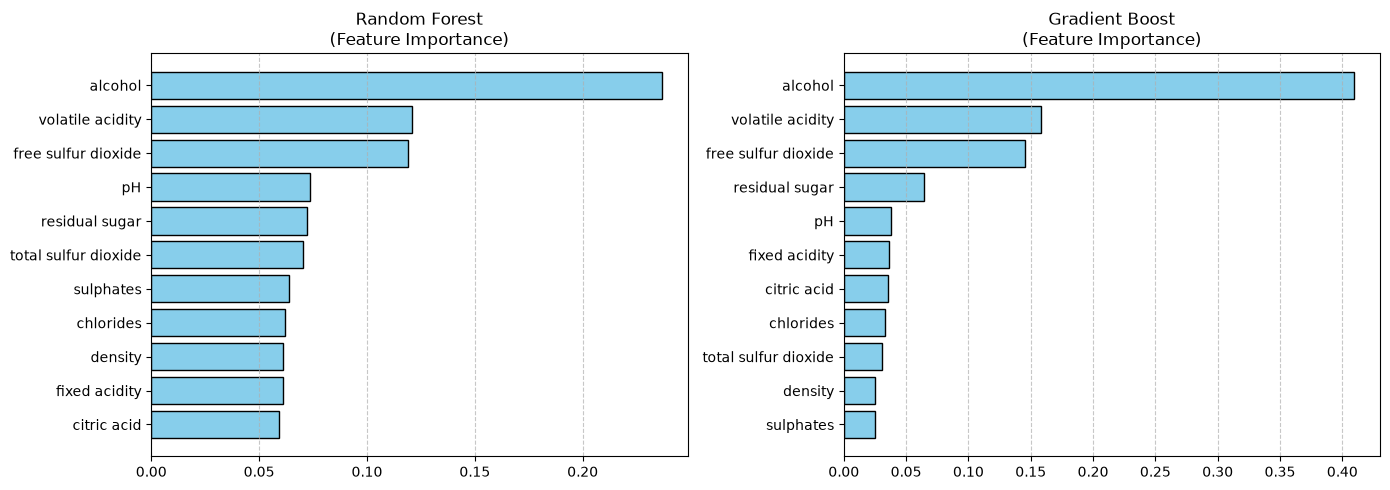

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

trained_models = {
    "Random Forest": randomforest, 
    "Gradient Boost": gradientboost
}

for idx, (name, pipeline) in enumerate(trained_models.items()):

    importances = pipeline.named_steps["model"].feature_importances_
    indices = np.argsort(importances)
    
    axes[idx].barh(range(len(indices)), importances[indices], color='skyblue', edgecolor='black')
    axes[idx].set_yticks(range(len(indices)))
    axes[idx].set_yticklabels(X.columns[indices])
    axes[idx].set_title(f"{name}\n(Feature Importance)")
    axes[idx].grid(axis='x', linestyle='--', alpha=0.7)


plt.tight_layout()
plt.show()

### Коэффициенты линейной регрессии и Ridge на полиномиальных признаках

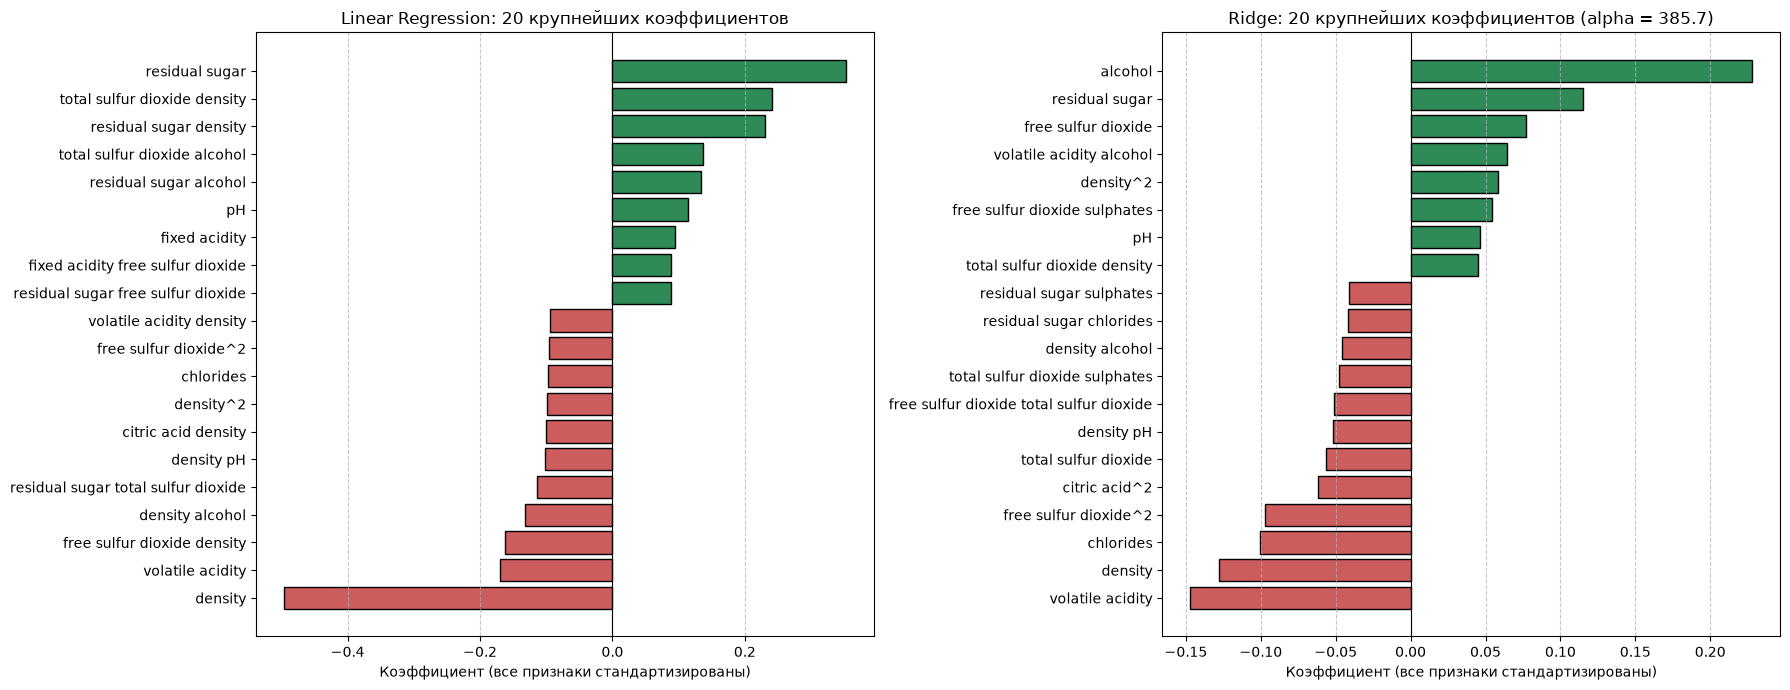

Всего признаков после PolynomialFeatures: 77


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, (name, pipe) in zip(axes, {"Linear Regression": linreg, "Ridge": linreg_poly}.items()):
    poly = pipe.named_steps["polynomialfeatures"]
    model = pipe.steps[-1][1]

    # имена alcohol volatile acidity это произведение двух признаков, alcohol^2 это квадрат
    coef = pd.Series(model.coef_, index=poly.get_feature_names_out(X.columns)).drop("1")
    top = coef.abs().sort_values(ascending=False).head(20).index
    top_coef = coef[top].sort_values()

    colors = np.where(top_coef > 0, "seagreen", "indianred")
    ax.barh(top_coef.index, top_coef.values, color=colors, edgecolor="black")
    ax.axvline(0, color="black", linewidth=0.8)
    title = f"{name}: 20 крупнейших коэффициентов"
    if hasattr(model, "alpha_"):
        title += f" (alpha = {model.alpha_:.1f})"
    ax.set_title(title)
    ax.set_xlabel("Коэффициент (все признаки стандартизированы)")
    ax.grid(axis="x", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

print("Всего признаков после PolynomialFeatures:", len(coef))

## Анализ ошибок лучшей модели (Random Forest)

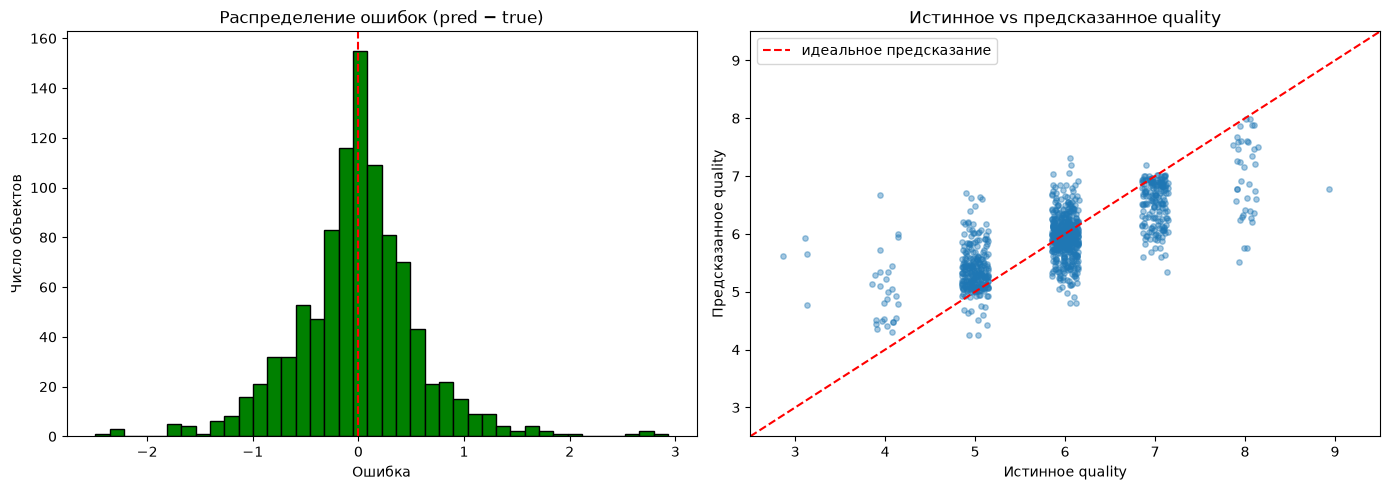

count    980.000
mean      -0.009
std        0.584
min       -2.490
25%       -0.300
50%        0.000
75%        0.290
max        2.930
Name: error, dtype: float64
Доля объектов с |ошибкой| < 0.5: 0.7
Доля объектов с |ошибкой| > 1:   0.085


In [20]:
rf_pred = randomforest.predict(X_test)

errors = pd.DataFrame({"true": y_test, "pred": rf_pred})
errors["error"] = errors["pred"] - errors["true"]
errors["abs_error"] = errors["error"].abs()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(errors["error"], bins=40, color="green", edgecolor="black")
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Распределение ошибок (pred − true)")
axes[0].set_xlabel("Ошибка")
axes[0].set_ylabel("Число объектов")

# небольшой случайный сдвиг по x, иначе точки с одинаковым quality сливаются в одну линию
jitter = np.random.default_rng(27).uniform(-0.15, 0.15, len(errors))
lims = [y.min() - 0.5, y.max() + 0.5]
axes[1].scatter(errors["true"] + jitter, errors["pred"], alpha=0.4, s=15)
axes[1].plot(lims, lims, "r--", label="идеальное предсказание")
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)
axes[1].set_title("Истинное vs предсказанное quality")
axes[1].set_xlabel("Истинное quality")
axes[1].set_ylabel("Предсказанное quality")
axes[1].legend()

plt.tight_layout()
plt.show()

print(errors["error"].describe().round(3))
print("Доля объектов с |ошибкой| < 0.5:", round((errors["abs_error"] < 0.5).mean(), 3))
print("Доля объектов с |ошибкой| > 1:  ", round((errors["abs_error"] > 1).mean(), 3))

### Объекты с наибольшими ошибками

In [21]:
worst = errors.sort_values("abs_error", ascending=False).head(10)
display(worst.join(X_test).round(3))

# средние значения признаков для каждого quality в train — чтобы понять, на какой класс "похож" объект
key_features = ["alcohol", "volatile acidity", "free sulfur dioxide", "residual sugar", "density"]
display(X_train.groupby(y_train)[key_features].mean().round(3))

,true,pred,error,abs_error,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
3087,3,5.93,2.93,2.93,6.1,0.200,0.34,9.5,0.041,38.0,201.0,0.995,3.14,0.44,10.1
3417,4,6.68,2.68,2.68,6.7,0.640,0.30,1.2,0.030,18.0,76.0,0.989,3.16,0.60,12.9
3810,3,5.66,2.66,2.66,6.8,0.260,0.34,15.1,0.060,42.0,162.0,0.997,3.24,0.52,10.5
3265,3,5.62,2.62,2.62,4.2,0.215,0.23,5.1,0.041,64.0,157.0,0.997,3.42,0.44,8.0
904,8,5.51,-2.49,2.49,6.9,0.210,0.28,2.4,0.056,49.0,159.0,0.994,3.02,0.47,8.8
1216,8,5.75,-2.25,2.25,8.2,0.370,0.36,1.0,0.034,17.0,93.0,0.991,3.04,0.32,11.7
1219,8,5.75,-2.25,2.25,8.2,0.370,0.36,1.0,0.034,17.0,93.0,0.991,3.04,0.32,11.7
1605,9,6.77,-2.23,2.23,7.1,0.260,0.49,2.2,0.032,31.0,113.0,0.990,3.37,0.42,12.9
176,4,6.00,2.00,2.00,7.2,0.320,0.47,5.1,0.044,19.0,65.0,0.991,3.03,0.41,12.6
690,4,5.95,1.95,1.95,6.9,0.200,0.34,1.9,0.043,25.0,136.0,0.994,3.31,0.60,10.1


,alcohol,volatile acidity,free sulfur dioxide,residual sugar,density
quality,,,,,
3,10.575,0.334,55.594,5.472,0.994
4,10.138,0.373,23.412,4.834,0.994
5,9.823,0.303,36.237,7.269,0.995
6,10.582,0.262,35.602,6.469,0.994
7,11.348,0.261,34.413,5.182,0.992
8,11.658,0.281,36.131,5.626,0.992
9,12.000,0.308,34.000,4.600,0.992


### Качество модели для разных значений quality

,n_train,n_test,mean_pred,mean_error,MAE,RMSE
true,,,,,,
3,16,4,5.495,2.495,2.495,2.533
4,136,27,5.007,1.007,1.007,1.161
5,1193,264,5.372,0.372,0.411,0.536
6,1727,471,5.958,-0.042,0.288,0.383
7,705,175,6.526,-0.474,0.477,0.611
8,137,38,6.980,-1.020,1.020,1.223
9,4,1,6.770,-2.230,2.230,2.230


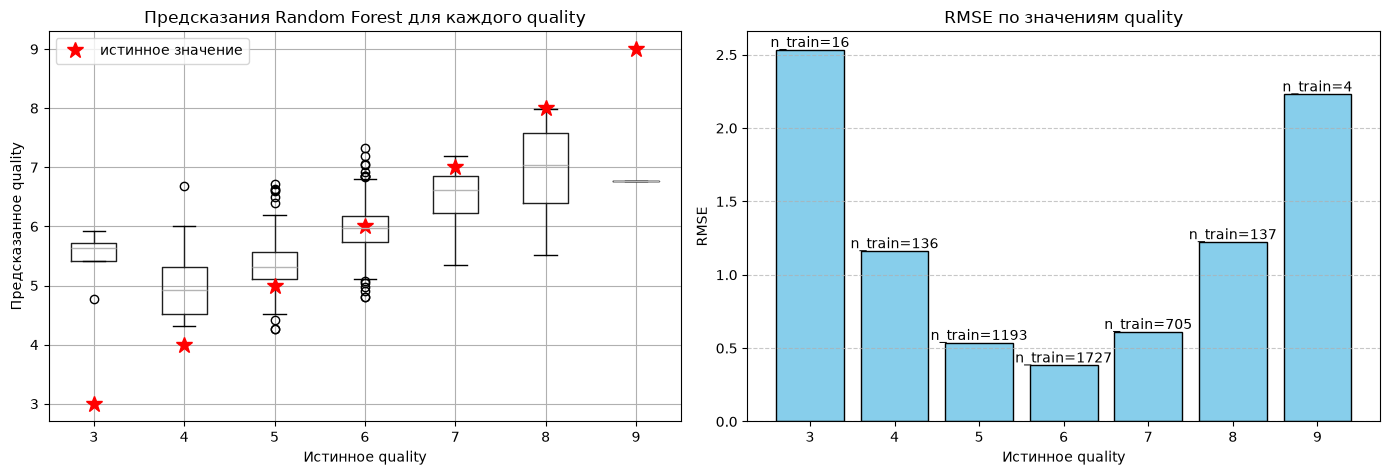

In [22]:
by_quality = errors.groupby("true").agg(
    n_test=("error", "size"),
    mean_pred=("pred", "mean"),
    mean_error=("error", "mean"),
    MAE=("abs_error", "mean"),
    RMSE=("error", lambda e: np.sqrt(np.mean(e ** 2))),
)
by_quality.insert(0, "n_train", y_train.value_counts().reindex(by_quality.index, fill_value=0))
display(by_quality.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

errors.boxplot(column="pred", by="true", ax=axes[0])
axes[0].plot(range(1, len(by_quality) + 1), by_quality.index, "r*", markersize=12, label="истинное значение")
axes[0].set_title("Предсказания Random Forest для каждого quality")
axes[0].set_xlabel("Истинное quality")
axes[0].set_ylabel("Предсказанное quality")
axes[0].legend()
fig.suptitle("")

axes[1].bar(by_quality.index.astype(str), by_quality["RMSE"], color="skyblue", edgecolor="black")
for i, (r, n) in enumerate(zip(by_quality["RMSE"], by_quality["n_train"])):
    axes[1].text(i, r + 0.02, f"n_train={n}", ha="center")
axes[1].set_title("RMSE по значениям quality")
axes[1].set_xlabel("Истинное quality")
axes[1].set_ylabel("RMSE")
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()